# 12C — Corrected Baseline Rebuild

**Purpose:** rebuild the original next-day hotspot baseline on the **spatially corrected Indonesian Kalimantan domain** produced by Notebook 12B.

This notebook is necessary before wind/GAT experiments so that every later model is compared on the **same corrected nodes, dates, labels, and features**.

---

## Main questions

1. After correcting the spatial domain, is Logistic Regression still a strong baseline?
2. How much does weather add beyond local fire history on the corrected domain?
3. How different are the corrected class balance and validation metrics from the original 272-cell benchmark?
4. Are 3-day / 7-day Emerging events numerous enough to remain a meaningful secondary diagnostic?

---

## Fair-comparison rules

This notebook deliberately preserves the original benchmark design:

- same **10 fire-history features**
- same **10 weather features**
- same **20-feature benchmark**
- same weather nearest-cell mapping using Haversine distance
- same temporal split:
  - Train: 2026-05-08 → 2026-07-31
  - Validation: 2026-08-01 → 2026-08-31
  - Test: 2026-09-01 → 2026-09-10
- same Logistic Regression configuration:
  - `StandardScaler`
  - `class_weight="balanced"`
  - `max_iter=1000`
  - `random_state=42`
- primary metric: **PR-AUC / Average Precision**

The September test set is **not inspected by default** while the research design is still being developed.

---

## Inputs expected from Notebook 12B

```text
data/intermediate/spatial_corrected/
├── fire_kalimantan_cell_day_corrected.csv
├── fire_kalimantan_model_panel_corrected.csv
└── kalimantan_graph_nodes_corrected.csv
```

Weather is reused from the existing Notebook 04 intermediate table:

```text
data/intermediate/weather_kalimantan_rich_daily.csv
```

In [13]:
# 1. Imports and reproducibility

from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    precision_recall_curve,
)

try:
    import joblib
except ImportError:
    joblib = None

warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)

print("Imports ready.")

Imports ready.


## 2. Resolve project paths

The notebook searches common local and Colab locations.

It does **not** overwrite the original 272-cell processed dataset.

In [14]:
# 2. Project paths

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for candidate in candidate_roots:
    corrected_candidate = (
        candidate
        / "data"
        / "intermediate"
        / "spatial_corrected"
        / "fire_kalimantan_cell_day_corrected.csv"
    )
    weather_candidate = (
        candidate
        / "data"
        / "intermediate"
        / "weather_kalimantan_rich_daily.csv"
    )

    if corrected_candidate.exists() and weather_candidate.exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root could not be detected automatically.\n"
        "Set PROJECT_ROOT manually to the folder containing "
        "data/intermediate/spatial_corrected and weather_kalimantan_rich_daily.csv."
    )

INTERMEDIATE_DIR = PROJECT_ROOT / "data" / "intermediate"
CORRECTED_DIR = INTERMEDIATE_DIR / "spatial_corrected"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "spatial_corrected"

CORRECTED_FIRE_PATH = (
    CORRECTED_DIR
    / "fire_kalimantan_cell_day_corrected.csv"
)

CORRECTED_MODEL_PANEL_PATH = (
    CORRECTED_DIR
    / "fire_kalimantan_model_panel_corrected.csv"
)

CORRECTED_NODES_PATH = (
    CORRECTED_DIR
    / "kalimantan_graph_nodes_corrected.csv"
)

WEATHER_INPUT = (
    INTERMEDIATE_DIR
    / "weather_kalimantan_rich_daily.csv"
)

ORIGINAL_ML_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "karhut_ml_dataset_kalimantan.csv"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "corrected_baseline"
)

FIGURES_DIR = RESULTS_DIR / "figures"
MODELS_DIR = RESULTS_DIR / "models"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT       :", PROJECT_ROOT)
print("Corrected fire     :", CORRECTED_FIRE_PATH)
print("Corrected panel    :", CORRECTED_MODEL_PANEL_PATH)
print("Corrected nodes    :", CORRECTED_NODES_PATH)
print("Weather daily      :", WEATHER_INPUT)
print("Original ML        :", ORIGINAL_ML_PATH)
print("Results            :", RESULTS_DIR)

PROJECT_ROOT       : c:\Users\Asus\Documents\skripsi-karhut
Corrected fire     : c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\spatial_corrected\fire_kalimantan_cell_day_corrected.csv
Corrected panel    : c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\spatial_corrected\fire_kalimantan_model_panel_corrected.csv
Corrected nodes    : c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\spatial_corrected\kalimantan_graph_nodes_corrected.csv
Weather daily      : c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\weather_kalimantan_rich_daily.csv
Original ML        : c:\Users\Asus\Documents\skripsi-karhut\data\processed\karhut_ml_dataset_kalimantan.csv
Results            : c:\Users\Asus\Documents\skripsi-karhut\model_results\corrected_baseline


## 3. Load corrected fire panel, corrected nodes, and daily weather

The **full corrected fire panel** is used to recreate lag/rolling features from May 1 onward.

The shorter corrected model panel from Notebook 12B is loaded only for consistency checks on targets and Emerging labels.

In [15]:
# 3. Load inputs

required_paths = {
    "corrected fire panel": CORRECTED_FIRE_PATH,
    "corrected model panel": CORRECTED_MODEL_PANEL_PATH,
    "corrected graph nodes": CORRECTED_NODES_PATH,
    "weather daily": WEATHER_INPUT,
}

for name, path in required_paths.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {name}: {path}")

fire = pd.read_csv(
    CORRECTED_FIRE_PATH,
    parse_dates=["date"],
)

model_panel_12b = pd.read_csv(
    CORRECTED_MODEL_PANEL_PATH,
    parse_dates=["date", "target_date"],
)

nodes = pd.read_csv(
    CORRECTED_NODES_PATH,
)

weather = pd.read_csv(
    WEATHER_INPUT,
    parse_dates=["date"],
)

fire = (
    fire
    .sort_values(["cell_id", "date"])
    .reset_index(drop=True)
)

model_panel_12b = (
    model_panel_12b
    .sort_values(["cell_id", "date"])
    .reset_index(drop=True)
)

print("Corrected full fire panel :", fire.shape)
print("Corrected 12B model panel :", model_panel_12b.shape)
print("Corrected graph nodes     :", nodes.shape)
print("Weather daily             :", weather.shape)
print()
print(
    "Fire date range:",
    fire["date"].min().date(),
    "→",
    fire["date"].max().date(),
)
print("Fire unique cells:", fire["cell_id"].nunique())
print("Node-table cells :", nodes["cell_id"].nunique())

Corrected full fire panel : (12060, 16)
Corrected 12B model panel : (11340, 17)
Corrected graph nodes     : (90, 9)
Weather daily             : (13400, 14)

Fire date range: 2026-05-01 → 2026-09-11
Fire unique cells: 90
Node-table cells : 90


## 4. Input integrity checks

Expected corrected-domain properties from Notebook 12B:

- 90 valid graph nodes under the current 20% overlap rule
- 134 full fire-panel dates
- no duplicate `(cell_id, date)` rows
- the same node IDs in the full fire panel and graph-node table

In [16]:
# 4. Integrity checks

required_fire_cols = {
    "region",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "date",
    "fire_count",
    "frp_sum",
    "fire_active",
    "target_fire_active_t1",
}

missing_fire = sorted(
    required_fire_cols - set(fire.columns)
)

if missing_fire:
    raise ValueError(
        f"Corrected fire panel is missing columns: {missing_fire}"
    )

required_node_cols = {
    "node_index",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "kalimantan_overlap_fraction",
}

missing_nodes = sorted(
    required_node_cols - set(nodes.columns)
)

if missing_nodes:
    raise ValueError(
        f"Corrected node table is missing columns: {missing_nodes}"
    )

assert fire.duplicated(["cell_id", "date"]).sum() == 0
assert nodes["cell_id"].duplicated().sum() == 0

fire_cells = set(fire["cell_id"].unique())
node_cells = set(nodes["cell_id"].unique())

if fire_cells != node_cells:
    raise AssertionError(
        "Corrected fire panel and corrected node table do not contain the same cells."
    )

print("Unique corrected cells :", len(fire_cells))
print("Unique dates           :", fire["date"].nunique())
print("Duplicate cell-dates   :", fire.duplicated(["cell_id", "date"]).sum())
print("Node ID consistency    : PASSED")

if len(fire_cells) != 90:
    print(
        "NOTE: corrected node count is not 90. "
        "This is okay only if Notebook 12B was rerun with a different overlap threshold."
    )

Unique corrected cells : 90
Unique dates           : 134
Duplicate cell-dates   : 0
Node ID consistency    : PASSED


# PART A — Rebuild the exact benchmark features

## 5. Recreate the 10 fire-history features

This follows the original Notebook 04 logic exactly:

### Explicit lags

- `fire_count_lag1`
- `fire_count_lag3`
- `fire_count_lag7`
- `frp_sum_lag1`
- `frp_sum_lag3`
- `frp_sum_lag7`

### Shift-then-roll features

- `fire_count_roll3`
- `fire_count_roll7`
- `frp_sum_roll3`
- `frp_sum_roll7`

The rolling windows are shifted first, so they **do not include the current row's fire value**.

In [17]:
# 5. Fire-history feature engineering

fire_features_df = fire.copy()

for source_col in ["fire_count", "frp_sum"]:
    for lag in [1, 3, 7]:
        fire_features_df[f"{source_col}_lag{lag}"] = (
            fire_features_df
            .groupby("cell_id")[source_col]
            .shift(lag)
        )

shifted_fire_count = (
    fire_features_df
    .groupby("cell_id")["fire_count"]
    .shift(1)
)

shifted_frp_sum = (
    fire_features_df
    .groupby("cell_id")["frp_sum"]
    .shift(1)
)

fire_features_df["fire_count_roll3"] = (
    shifted_fire_count
    .groupby(fire_features_df["cell_id"])
    .rolling(window=3, min_periods=3)
    .sum()
    .reset_index(level=0, drop=True)
)

fire_features_df["fire_count_roll7"] = (
    shifted_fire_count
    .groupby(fire_features_df["cell_id"])
    .rolling(window=7, min_periods=7)
    .sum()
    .reset_index(level=0, drop=True)
)

fire_features_df["frp_sum_roll3"] = (
    shifted_frp_sum
    .groupby(fire_features_df["cell_id"])
    .rolling(window=3, min_periods=3)
    .sum()
    .reset_index(level=0, drop=True)
)

fire_features_df["frp_sum_roll7"] = (
    shifted_frp_sum
    .groupby(fire_features_df["cell_id"])
    .rolling(window=7, min_periods=7)
    .sum()
    .reset_index(level=0, drop=True)
)

fire_history_features = [
    "fire_count_lag1",
    "fire_count_lag3",
    "fire_count_lag7",
    "frp_sum_lag1",
    "frp_sum_lag3",
    "frp_sum_lag7",
    "fire_count_roll3",
    "fire_count_roll7",
    "frp_sum_roll3",
    "frp_sum_roll7",
]

print("Fire-history features:", len(fire_history_features))

display(
    fire_features_df[
        [
            "cell_id",
            "date",
            "fire_count",
            "frp_sum",
            *fire_history_features,
            "target_fire_active_t1",
        ]
    ].head(12)
)

Fire-history features: 10


,cell_id,date,fire_count,frp_sum,fire_count_lag1,fire_count_lag3,fire_count_lag7,frp_sum_lag1,frp_sum_lag3,frp_sum_lag7,fire_count_roll3,fire_count_roll7,frp_sum_roll3,frp_sum_roll7,target_fire_active_t1
0,Kalimantan_-0.75_109.50,2026-05-01,0,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
1,Kalimantan_-0.75_109.50,2026-05-02,0,0.00,0.0,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2,Kalimantan_-0.75_109.50,2026-05-03,0,0.00,0.0,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN,0.0
3,Kalimantan_-0.75_109.50,2026-05-04,0,0.00,0.0,0.0,NaN,0.00,0.00,NaN,0.0,NaN,0.00,NaN,0.0
4,Kalimantan_-0.75_109.50,2026-05-05,0,0.00,0.0,0.0,NaN,0.00,0.00,NaN,0.0,NaN,0.00,NaN,1.0
5,Kalimantan_-0.75_109.50,2026-05-06,1,2.66,0.0,0.0,NaN,0.00,0.00,NaN,0.0,NaN,0.00,NaN,0.0
6,Kalimantan_-0.75_109.50,2026-05-07,0,0.00,1.0,0.0,NaN,2.66,0.00,NaN,1.0,NaN,2.66,NaN,0.0
7,Kalimantan_-0.75_109.50,2026-05-08,0,0.00,0.0,0.0,0.0,0.00,0.00,0.0,1.0,1.0,2.66,2.66,0.0
8,Kalimantan_-0.75_109.50,2026-05-09,0,0.00,0.0,1.0,0.0,0.00,2.66,0.0,1.0,1.0,2.66,2.66,0.0
9,Kalimantan_-0.75_109.50,2026-05-10,0,0.00,0.0,0.0,0.0,0.00,0.00,0.0,0.0,1.0,0.00,2.66,0.0


## 6. Fire-history leakage checks

The checks below verify that `lag1` exactly equals the previous cell-day and that the rolling features exclude the current day.

In [18]:
# 6. Fire-history leakage checks

expected_lag1 = (
    fire_features_df
    .groupby("cell_id")["fire_count"]
    .shift(1)
)

lag1_mismatch = (
    ~np.isclose(
        fire_features_df["fire_count_lag1"].fillna(-999999),
        expected_lag1.fillna(-999999),
    )
).sum()

print("Lag-1 mismatches:", lag1_mismatch)

if lag1_mismatch != 0:
    raise AssertionError("Lag-1 leakage/integrity check failed.")

# Spot-check one cell's rolling sums manually.
sample_cell = fire_features_df["cell_id"].iloc[0]
sample = (
    fire_features_df[
        fire_features_df["cell_id"].eq(sample_cell)
    ]
    .reset_index(drop=True)
)

rolling_check_rows = []

for idx in range(7, min(12, len(sample))):
    expected_roll7 = (
        sample.loc[idx - 7: idx - 1, "fire_count"].sum()
    )
    actual_roll7 = sample.loc[idx, "fire_count_roll7"]

    rolling_check_rows.append({
        "cell_id": sample_cell,
        "date": sample.loc[idx, "date"],
        "expected_roll7": expected_roll7,
        "actual_roll7": actual_roll7,
        "match": np.isclose(expected_roll7, actual_roll7),
    })

rolling_check = pd.DataFrame(rolling_check_rows)
display(rolling_check)

assert rolling_check["match"].all()

print("Fire-history leakage checks: PASSED")

Lag-1 mismatches: 0


,cell_id,date,expected_roll7,actual_roll7,match
0,Kalimantan_-0.75_109.50,2026-05-08,1,1.0,True
1,Kalimantan_-0.75_109.50,2026-05-09,1,1.0,True
2,Kalimantan_-0.75_109.50,2026-05-10,1,1.0,True
3,Kalimantan_-0.75_109.50,2026-05-11,1,1.0,True
4,Kalimantan_-0.75_109.50,2026-05-12,1,1.0,True


Fire-history leakage checks: PASSED


## 7. Define the same 10 weather benchmark features

Weather conditions on day `t` are used for prediction of target day `t+1`, matching the existing benchmark design.

In [19]:
# 7. Weather benchmark columns

weather_features = [
    "temperature_mean",
    "temperature_max",
    "relative_humidity_mean",
    "precipitation_sum",
    "boundary_layer_height_mean",
    "vapour_pressure_deficit_mean",
    "wind_speed_mean",
    "wind_speed_max",
    "wind_u_mean",
    "wind_v_mean",
]

required_weather_cols = {
    "lat",
    "lon",
    "date",
    *weather_features,
}

missing_weather = sorted(
    required_weather_cols - set(weather.columns)
)

if missing_weather:
    raise ValueError(
        f"Daily weather table is missing columns: {missing_weather}"
    )

weather = weather.rename(
    columns={
        "lat": "weather_lat",
        "lon": "weather_lon",
    }
)

duplicate_weather_rows = weather.duplicated(
    ["date", "weather_lat", "weather_lon"]
).sum()

print("Weather features:", len(weather_features))
print("Duplicate weather date-grid rows:", duplicate_weather_rows)

if duplicate_weather_rows:
    raise AssertionError(
        "Weather daily table contains duplicate date-grid rows."
    )

Weather features: 10
Duplicate weather date-grid rows: 0


## 8. Create corrected-node → nearest-weather mapping

The corrected nodes remain on the 0.75° analysis grid while weather remains on the 1.25° grid.

To preserve the original benchmark, each corrected fire cell is mapped once to the nearest weather cell using **Haversine distance**.

In [20]:
# 8. Haversine nearest-weather mapping

def haversine_km(
    lat1,
    lon1,
    lat2,
    lon2,
):
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2.0) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2.0) ** 2
    )

    return (
        6371.0088
        * 2
        * np.arcsin(np.sqrt(a))
    )

weather_cells = (
    weather[
        ["weather_lat", "weather_lon"]
    ]
    .drop_duplicates()
    .sort_values(
        ["weather_lat", "weather_lon"]
    )
    .reset_index(drop=True)
)

corrected_fire_cells = (
    fire_features_df[
        ["cell_id", "grid_lat", "grid_lon"]
    ]
    .drop_duplicates()
    .sort_values(
        ["grid_lat", "grid_lon"]
    )
    .reset_index(drop=True)
)

weather_lat_values = (
    weather_cells["weather_lat"].to_numpy()
)
weather_lon_values = (
    weather_cells["weather_lon"].to_numpy()
)

mapping_rows = []

for row in corrected_fire_cells.itertuples(index=False):
    distances = haversine_km(
        row.grid_lat,
        row.grid_lon,
        weather_lat_values,
        weather_lon_values,
    )

    nearest_idx = int(
        np.argmin(distances)
    )

    mapping_rows.append({
        "cell_id": row.cell_id,
        "grid_lat": row.grid_lat,
        "grid_lon": row.grid_lon,
        "weather_lat": weather_cells.iloc[nearest_idx]["weather_lat"],
        "weather_lon": weather_cells.iloc[nearest_idx]["weather_lon"],
        "weather_distance_km": float(distances[nearest_idx]),
    })

weather_mapping = pd.DataFrame(
    mapping_rows
)

print("Corrected node mapping rows:", len(weather_mapping))

display(
    weather_mapping[
        "weather_distance_km"
    ].describe()
)

print(
    "Max distance:",
    round(
        weather_mapping["weather_distance_km"].max(),
        2,
    ),
    "km",
)

Corrected node mapping rows: 90


count    90.000000
mean     51.477725
std      18.670933
min       0.000000
25%      39.299867
50%      55.597540
75%      62.156232
max      78.626296
Name: weather_distance_km, dtype: float64

Max distance: 78.63 km


## 9. Merge corrected fire-history features with weather

The merge is validated as:

- many corrected cell-days → one static cell-to-weather mapping
- many corrected cell-days → one weather row for each `(date, weather_lat, weather_lon)`

In [21]:
# 9. Weather merge

feature_df = fire_features_df.merge(
    weather_mapping[
        [
            "cell_id",
            "weather_lat",
            "weather_lon",
            "weather_distance_km",
        ]
    ],
    on="cell_id",
    how="left",
    validate="many_to_one",
)

feature_df = feature_df.merge(
    weather[
        [
            "date",
            "weather_lat",
            "weather_lon",
            *weather_features,
        ]
    ],
    on=[
        "date",
        "weather_lat",
        "weather_lon",
    ],
    how="left",
    validate="many_to_one",
)

weather_missing_rows = (
    feature_df[weather_features]
    .isna()
    .any(axis=1)
    .sum()
)

print("Rows after weather merge:", len(feature_df))
print("Rows with missing benchmark weather:", weather_missing_rows)

if weather_missing_rows:
    display(
        feature_df[
            feature_df[
                weather_features
            ].isna().any(axis=1)
        ][
            [
                "cell_id",
                "date",
                "grid_lat",
                "grid_lon",
                "weather_lat",
                "weather_lon",
                *weather_features,
            ]
        ].head(20)
    )

Rows after weather merge: 12060
Rows with missing benchmark weather: 0


## 10. Build the same 20-feature benchmark dataset

Rows are retained only when:

- all 10 fire-history features are available;
- all 10 benchmark weather features are available;
- `target_fire_active_t1` is available.

With 90 nodes and 126 usable prediction dates (May 8–Sep 10), the expected size is:

\[
90 	imes 126 = 11{,}340 	ext{ rows}
\]

In [22]:
# 10. Final corrected model-ready dataset

features_10 = fire_history_features
features_20 = fire_history_features + weather_features
target_col = "target_fire_active_t1"

assert len(features_10) == 10
assert len(weather_features) == 10
assert len(features_20) == 20
assert target_col not in features_20

before_drop = len(feature_df)

ml_corrected = (
    feature_df
    .dropna(
        subset=features_20 + [target_col]
    )
    .copy()
    .sort_values(
        ["cell_id", "date"]
    )
    .reset_index(drop=True)
)

ml_corrected[target_col] = (
    ml_corrected[target_col]
    .astype(int)
)

print("Rows before drop:", before_drop)
print("Rows after drop :", len(ml_corrected))
print(
    "Date range:",
    ml_corrected["date"].min().date(),
    "→",
    ml_corrected["date"].max().date(),
)
print(
    "Unique cells:",
    ml_corrected["cell_id"].nunique(),
)
print(
    "Overall positive rate:",
    round(
        ml_corrected[target_col].mean(),
        6,
    ),
)

expected_rows = (
    ml_corrected["cell_id"].nunique()
    * ml_corrected["date"].nunique()
)

print("Cell × date expected rows:", expected_rows)

if len(ml_corrected) != expected_rows:
    print(
        "WARNING: corrected model-ready data are not a complete cell × date panel."
    )

Rows before drop: 12060
Rows after drop : 11340
Date range: 2026-05-08 → 2026-09-10
Unique cells: 90
Overall positive rate: 0.397002
Cell × date expected rows: 11340


## 11. Verify corrected targets and event labels against Notebook 12B

The target values should be identical to Notebook 12B for the same `(cell_id, date)` rows.

Notebook 12B's `event_type_3d` and `event_type_7d` labels are merged back in only for secondary diagnostics.

In [23]:
# 11. Target/event consistency with Notebook 12B

event_cols = [
    "cell_id",
    "date",
    "target_fire_active_t1",
    "active_days_prev3_incl_t",
    "active_days_prev7_incl_t",
    "event_type_3d",
    "event_type_7d",
    "target_date",
]

missing_event_cols = [
    c
    for c in event_cols
    if c not in model_panel_12b.columns
]

if missing_event_cols:
    raise ValueError(
        f"Notebook 12B model panel is missing: {missing_event_cols}"
    )

# Bersihkan sisa merge lama kalau ada
cols_to_drop = []

for col in ml_corrected.columns:
    if (
        col in [
            "active_days_prev3_incl_t",
            "active_days_prev7_incl_t",
            "event_type_3d",
            "event_type_7d",
            "target_date",
            "target_12b_check",
        ]
        or col.endswith("_x")
        or col.endswith("_y")
        or col.endswith("_12b_check")
    ):
        if col != target_col:
            cols_to_drop.append(col)

ml_corrected = ml_corrected.drop(
    columns=list(set(cols_to_drop)),
    errors="ignore",
)

# Ambil event labels yang authoritative dari Notebook 12B
event_ref = model_panel_12b[event_cols].copy()

event_ref = event_ref.rename(
    columns={
        "target_fire_active_t1": "target_12b_check",
    }
)

# Merge ulang dengan nama kolom bersih
ml_corrected = ml_corrected.merge(
    event_ref,
    on=["cell_id", "date"],
    how="left",
    validate="one_to_one",
)

# Cek kolom hasil merge
required_after_merge = [
    "target_12b_check",
    "active_days_prev3_incl_t",
    "active_days_prev7_incl_t",
    "event_type_3d",
    "event_type_7d",
    "target_date",
]

missing_after_merge = [
    c
    for c in required_after_merge
    if c not in ml_corrected.columns
]

if missing_after_merge:
    raise AssertionError(
        f"Required columns missing after merge: {missing_after_merge}"
    )

# Cek target
missing_target_check = (
    ml_corrected["target_12b_check"]
    .isna()
    .sum()
)

print(
    "Missing Notebook 12B target checks:",
    missing_target_check,
)

target_mismatch = (
    ml_corrected[target_col].astype(int)
    != ml_corrected["target_12b_check"].astype(int)
).sum()

print(
    "Target mismatches vs Notebook 12B:",
    target_mismatch,
)

if target_mismatch:
    raise AssertionError(
        "Corrected feature table target does not match Notebook 12B."
    )

# Cek event labels
missing_event_labels = (
    ml_corrected[
        ["event_type_3d", "event_type_7d"]
    ]
    .isna()
    .any(axis=1)
    .sum()
)

print(
    "Rows with missing 12B event labels:",
    missing_event_labels,
)

if missing_event_labels:
    raise AssertionError(
        "Some rows are missing Notebook 12B event labels."
    )

print()
display(
    ml_corrected[
        [
            "cell_id",
            "date",
            target_col,
            "event_type_3d",
            "event_type_7d",
        ]
    ].head()
)

print()
print("Corrected target/event consistency: PASSED")

Missing Notebook 12B target checks: 0
Target mismatches vs Notebook 12B: 0
Rows with missing 12B event labels: 0



,cell_id,date,target_fire_active_t1,event_type_3d,event_type_7d
0,Kalimantan_-0.75_109.50,2026-05-08,0,Negative,Negative
1,Kalimantan_-0.75_109.50,2026-05-09,0,Negative,Negative
2,Kalimantan_-0.75_109.50,2026-05-10,0,Negative,Negative
3,Kalimantan_-0.75_109.50,2026-05-11,0,Negative,Negative
4,Kalimantan_-0.75_109.50,2026-05-12,0,Negative,Negative



Corrected target/event consistency: PASSED


## 12. Final leakage audit

The main corrected benchmark remains intentionally identical in feature meaning to the old baseline:

- `target_fire_active_t1` is never a feature;
- current-day `fire_count` and `fire_active` are not benchmark features;
- fire-history features use previous cell-days;
- weather uses day-`t` conditions to predict day `t+1`.

`event_type_*` is **diagnostic only** and is never used as a model feature.

In [24]:
# 12. Leakage audit

for forbidden in [
    "target_fire_active_t1",
    "target_12b_check",
    "fire_count",
    "fire_active",
    "event_type_3d",
    "event_type_7d",
]:
    assert forbidden not in features_20

feature_missing = (
    ml_corrected[features_20]
    .isna()
    .sum()
)

print("Missing values in 20 benchmark features:")
display(
    feature_missing.to_frame("missing")
)

assert feature_missing.sum() == 0

print("Basic corrected feature leakage/missing audit: PASSED")

Missing values in 20 benchmark features:


,missing
fire_count_lag1,0
fire_count_lag3,0
fire_count_lag7,0
frp_sum_lag1,0
frp_sum_lag3,0
frp_sum_lag7,0
fire_count_roll3,0
fire_count_roll7,0
frp_sum_roll3,0
frp_sum_roll7,0


Basic corrected feature leakage/missing audit: PASSED


# PART B — Temporal split and corrected Logistic Regression

## 13. Apply the original temporal split

No random split is used.

In [25]:
# 13. Temporal split

train_data = ml_corrected[
    ml_corrected["date"] < "2026-08-01"
].copy()

val_data = ml_corrected[
    (ml_corrected["date"] >= "2026-08-01")
    &
    (ml_corrected["date"] < "2026-09-01")
].copy()

test_data = ml_corrected[
    ml_corrected["date"] >= "2026-09-01"
].copy()

split_summary = pd.DataFrame({
    "Split": [
        "Train",
        "Validation",
        "Test",
    ],
    "Start": [
        train_data["date"].min(),
        val_data["date"].min(),
        test_data["date"].min(),
    ],
    "End": [
        train_data["date"].max(),
        val_data["date"].max(),
        test_data["date"].max(),
    ],
    "Rows": [
        len(train_data),
        len(val_data),
        len(test_data),
    ],
    "Positives": [
        int(train_data[target_col].sum()),
        int(val_data[target_col].sum()),
        int(test_data[target_col].sum()),
    ],
    "Positive Rate": [
        train_data[target_col].mean(),
        val_data[target_col].mean(),
        test_data[target_col].mean(),
    ],
})

display(split_summary)

,Split,Start,End,Rows,Positives,Positive Rate
0,Train,2026-05-08,2026-07-31,7650,1786,0.233464
1,Validation,2026-08-01,2026-08-31,2790,2091,0.749462
2,Test,2026-09-01,2026-09-10,900,625,0.694444


## 14. Event-count diagnostics after spatial correction

This does **not** change the main target.

It tells us whether Emerging events are numerous enough for meaningful subgroup analysis.

As a practical warning threshold, subgroup metrics based on fewer than 30 positive cases are flagged as unstable.

In [26]:
# 14. 3-day and 7-day event composition

def event_composition(
    df,
    event_col,
    split_name,
):
    positive = df[
        df[target_col].eq(1)
    ].copy()

    counts = (
        positive[event_col]
        .value_counts()
        .reindex(
            ["Persistent", "Emerging"],
            fill_value=0,
        )
    )

    total = int(
        counts.sum()
    )

    return pd.DataFrame({
        "Split": split_name,
        "Definition": event_col.replace("event_type_", ""),
        "Event Type": counts.index,
        "Count": counts.values,
        "Share of Positives": (
            counts.values / total
            if total > 0
            else np.nan
        ),
    })

event_composition_table = pd.concat([
    event_composition(
        train_data,
        "event_type_7d",
        "Train",
    ),
    event_composition(
        val_data,
        "event_type_7d",
        "Validation",
    ),
    event_composition(
        train_data,
        "event_type_3d",
        "Train",
    ),
    event_composition(
        val_data,
        "event_type_3d",
        "Validation",
    ),
], ignore_index=True)

event_composition_table["Stable N? (>=30)"] = (
    event_composition_table["Count"]
    >= 30
)

display(event_composition_table)

,Split,Definition,Event Type,Count,Share of Positives,Stable N? (>=30)
0,Train,7d,Persistent,1564,0.875700,True
1,Train,7d,Emerging,222,0.124300,True
2,Validation,7d,Persistent,2072,0.990913,True
3,Validation,7d,Emerging,19,0.009087,False
4,Train,3d,Persistent,1354,0.758119,True
5,Train,3d,Emerging,432,0.241881,True
6,Validation,3d,Persistent,2030,0.970827,True
7,Validation,3d,Emerging,61,0.029173,True


## 15. Evaluation helper

PR-AUC is threshold-free and remains the primary validation metric.

Threshold-based metrics are shown at 0.50 for continuity with the original baseline.

In [27]:
# 15. Evaluation functions

def metric_dict(
    y_true,
    y_prob,
    threshold=0.50,
):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob)
    y_pred = (
        y_prob >= threshold
    ).astype(int)

    return {
        "PR-AUC": average_precision_score(
            y_true,
            y_prob,
        ),
        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "F1": f1_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "Accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "Threshold": threshold,
    }


def find_best_f1_threshold(
    y_true,
    y_prob,
    start=0.10,
    stop=0.91,
    step=0.01,
):
    rows = []

    for threshold in np.arange(
        start,
        stop,
        step,
    ):
        threshold = round(
            float(threshold),
            2,
        )

        metrics = metric_dict(
            y_true,
            y_prob,
            threshold=threshold,
        )

        rows.append(metrics)

    result = pd.DataFrame(rows)

    result = (
        result
        .sort_values(
            [
                "F1",
                "Recall",
                "Threshold",
            ],
            ascending=[
                False,
                False,
                True,
            ],
        )
        .reset_index(drop=True)
    )

    return result

## 16. Fit corrected Fire-History-Only Logistic Regression

This isolates how much predictive information comes from the same 10 local fire-history variables after the spatial-domain correction.

In [28]:
# 16. Fire-history-only LR

def build_lr():
    return Pipeline([
        (
            "scaler",
            StandardScaler(),
        ),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=RANDOM_STATE,
            ),
        ),
    ])

X_train_fire = train_data[features_10]
X_val_fire = val_data[features_10]

y_train = (
    train_data[target_col]
    .astype(int)
)

y_val = (
    val_data[target_col]
    .astype(int)
)

lr_fire = build_lr()

start_time = time.perf_counter()

lr_fire.fit(
    X_train_fire,
    y_train,
)

lr_fire_train_seconds = (
    time.perf_counter()
    - start_time
)

prob_fire_val = (
    lr_fire
    .predict_proba(X_val_fire)[:, 1]
)

metrics_fire_val = metric_dict(
    y_val,
    prob_fire_val,
    threshold=0.50,
)

print(
    "Fire-History LR training seconds:",
    round(
        lr_fire_train_seconds,
        4,
    ),
)

display(
    pd.DataFrame([
        {
            "Model": "LR — Fire History Only",
            **metrics_fire_val,
        }
    ])
)

Fire-History LR training seconds: 0.1144


,Model,PR-AUC,Precision,Recall,F1,Accuracy,Threshold
0,LR — Fire History Only,0.954916,0.875227,0.922525,0.898254,0.843369,0.5


## 17. Fit corrected Fire-History + Weather Logistic Regression

This is the **main corrected LR benchmark** that later GAT variants should compare against.

In [29]:
# 17. Main 20-feature corrected LR

X_train_full = train_data[features_20]
X_val_full = val_data[features_20]

lr_full = build_lr()

start_time = time.perf_counter()

lr_full.fit(
    X_train_full,
    y_train,
)

lr_full_train_seconds = (
    time.perf_counter()
    - start_time
)

prob_full_val = (
    lr_full
    .predict_proba(X_val_full)[:, 1]
)

metrics_full_val = metric_dict(
    y_val,
    prob_full_val,
    threshold=0.50,
)

print(
    "Full LR training seconds:",
    round(
        lr_full_train_seconds,
        4,
    ),
)

display(
    pd.DataFrame([
        {
            "Model": "LR — Fire History + Weather",
            **metrics_full_val,
        }
    ])
)

Full LR training seconds: 0.0488


,Model,PR-AUC,Precision,Recall,F1,Accuracy,Threshold
0,LR — Fire History + Weather,0.955283,0.86602,0.939742,0.901376,0.845878,0.5


## 18. Corrected LR benchmark comparison

This is the central result of Notebook 12C.

It compares:

- the validation positive base rate;
- LR using local fire history only;
- LR using fire history + weather.

Because PR-AUC is prevalence-sensitive, the validation positive rate is shown explicitly.

In [30]:
# 18. Central validation comparison

validation_base_rate = (
    y_val.mean()
)

corrected_lr_comparison = pd.DataFrame([
    {
        "Model": "No-skill prevalence reference",
        "PR-AUC": validation_base_rate,
        "Precision": np.nan,
        "Recall": np.nan,
        "F1": np.nan,
        "Accuracy": np.nan,
        "Threshold": np.nan,
        "Training Seconds": 0.0,
    },
    {
        "Model": "LR — Fire History Only",
        **metrics_fire_val,
        "Training Seconds": lr_fire_train_seconds,
    },
    {
        "Model": "LR — Fire History + Weather",
        **metrics_full_val,
        "Training Seconds": lr_full_train_seconds,
    },
])

display(corrected_lr_comparison)

print(
    "Weather Δ PR-AUC:",
    round(
        metrics_full_val["PR-AUC"]
        - metrics_fire_val["PR-AUC"],
        6,
    ),
)

,Model,PR-AUC,Precision,Recall,F1,Accuracy,Threshold,Training Seconds
0,No-skill prevalence reference,0.749462,NaN,NaN,NaN,NaN,NaN,0.000000
1,LR — Fire History Only,0.954916,0.875227,0.922525,0.898254,0.843369,0.5,0.114377
2,LR — Fire History + Weather,0.955283,0.866020,0.939742,0.901376,0.845878,0.5,0.048814


Weather Δ PR-AUC: 0.000367


## 19. Persistence baseline on the corrected validation set

A simple persistence baseline predicts:

> next day active if the **current corrected cell-day** is active.

This baseline is reported because the dataset is now highly persistent during August.

It is **not** one of the 20 Logistic Regression features.

In [31]:
# 19. Persistence baseline

persistence_pred = (
    val_data["fire_active"]
    .astype(int)
    .to_numpy()
)

persistence_metrics = {
    "Model": "Persistence: fire_active(t) → target(t+1)",
    "Precision": precision_score(
        y_val,
        persistence_pred,
        zero_division=0,
    ),
    "Recall": recall_score(
        y_val,
        persistence_pred,
        zero_division=0,
    ),
    "F1": f1_score(
        y_val,
        persistence_pred,
        zero_division=0,
    ),
    "Accuracy": accuracy_score(
        y_val,
        persistence_pred,
    ),
}

display(
    pd.DataFrame([
        persistence_metrics
    ])
)

,Model,Precision,Recall,F1,Accuracy
0,Persistence: fire_active(t) → target(t+1),0.888622,0.885222,0.886919,0.830824


## 20. Validation Precision–Recall curves

The figure visually compares Fire-History-Only versus Fire-History + Weather on the corrected domain.

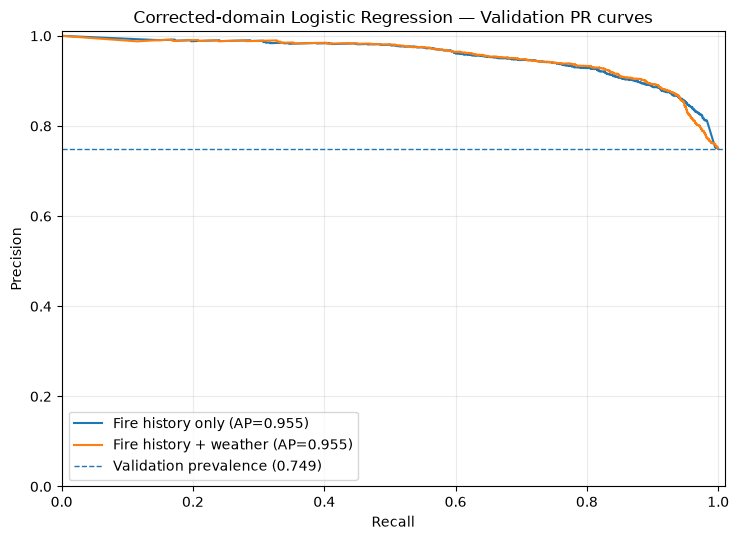

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\corrected_baseline\figures\corrected_lr_validation_pr_curve.png


In [32]:
# 20. Precision–Recall curves

precision_fire, recall_fire, _ = (
    precision_recall_curve(
        y_val,
        prob_fire_val,
    )
)

precision_full, recall_full, _ = (
    precision_recall_curve(
        y_val,
        prob_full_val,
    )
)

fig, ax = plt.subplots(
    figsize=(7.5, 5.5)
)

ax.plot(
    recall_fire,
    precision_fire,
    label=(
        "Fire history only "
        f"(AP={metrics_fire_val['PR-AUC']:.3f})"
    ),
)

ax.plot(
    recall_full,
    precision_full,
    label=(
        "Fire history + weather "
        f"(AP={metrics_full_val['PR-AUC']:.3f})"
    ),
)

ax.axhline(
    validation_base_rate,
    linestyle="--",
    linewidth=1,
    label=(
        "Validation prevalence "
        f"({validation_base_rate:.3f})"
    ),
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(
    "Corrected-domain Logistic Regression — Validation PR curves"
)
ax.set_xlim(0, 1.01)
ax.set_ylim(0, 1.01)
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

fig_path = (
    FIGURES_DIR
    / "corrected_lr_validation_pr_curve.png"
)

plt.savefig(
    fig_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print("Saved:", fig_path)

## 21. Best validation F1 threshold for the corrected full LR

This is a **validation-only** operating-threshold diagnostic.

It does not affect PR-AUC and it does not inspect the September test set.

In [33]:
# 21. Validation threshold selection

threshold_table = (
    find_best_f1_threshold(
        y_val,
        prob_full_val,
    )
)

best_threshold_row = (
    threshold_table.iloc[0]
)

display(
    threshold_table.head(15)
)

print(
    "Best validation F1 threshold:",
    best_threshold_row["Threshold"],
)

print(
    "Best validation F1:",
    round(
        best_threshold_row["F1"],
        6,
    ),
)

,PR-AUC,Precision,Recall,F1,Accuracy,Threshold
0,0.955283,0.869565,0.937351,0.902186,0.847670,0.51
1,0.955283,0.873599,0.932090,0.901897,0.848029,0.52
2,0.955283,0.866020,0.939742,0.901376,0.845878,0.50
3,0.955283,0.875507,0.928264,0.901114,0.847312,0.53
4,0.955283,0.877783,0.923960,0.900280,0.846595,0.54
5,0.955283,0.880146,0.920134,0.899696,0.846237,0.55
6,0.955283,0.890764,0.908656,0.899621,0.848029,0.58
7,0.955283,0.858824,0.942611,0.898769,0.840860,0.49
8,0.955283,0.885741,0.912004,0.898680,0.845878,0.57
9,0.955283,0.882434,0.915352,0.898592,0.845161,0.56


Best validation F1 threshold: 0.51
Best validation F1: 0.902186


# PART C — Secondary Emerging/Persistent diagnostics

## 22. Positive-subgroup recall

Recall is meaningful within these positive-only subgroups.

Precision is **not** computed per positive subgroup because there are no negative rows inside the subgroup denominator.

Interpret 7-day validation Emerging metrics very cautiously if the sample size remains below 30.

In [34]:
# 22. Persistent vs Emerging positive-subgroup recall

val_diag = (
    val_data
    .reset_index(drop=True)
    .copy()
)

val_diag["prob_fire"] = (
    prob_fire_val
)

val_diag["prob_full"] = (
    prob_full_val
)

def positive_subgroup_recall(
    df,
    event_col,
    probability_col,
    threshold=0.50,
):
    rows = []

    for event_type in [
        "Persistent",
        "Emerging",
    ]:
        group = df[
            (
                df[event_col].eq(event_type)
            )
            &
            (
                df[target_col].eq(1)
            )
        ].copy()

        n = len(group)

        if n == 0:
            recall = np.nan
            mean_prob = np.nan
        else:
            recall = (
                group[probability_col]
                .ge(threshold)
                .mean()
            )
            mean_prob = (
                group[probability_col]
                .mean()
            )

        rows.append({
            "Definition": event_col.replace(
                "event_type_",
                "",
            ),
            "Event Type": event_type,
            "N Positives": n,
            "Recall @0.50": recall,
            "Mean Predicted Probability": mean_prob,
            "Stable N? (>=30)": n >= 30,
        })

    return pd.DataFrame(rows)

subgroup_tables = []

for event_col in [
    "event_type_3d",
    "event_type_7d",
]:
    fire_part = positive_subgroup_recall(
        val_diag,
        event_col,
        "prob_fire",
        threshold=0.50,
    )
    fire_part.insert(
        0,
        "Model",
        "LR — Fire History Only",
    )

    full_part = positive_subgroup_recall(
        val_diag,
        event_col,
        "prob_full",
        threshold=0.50,
    )
    full_part.insert(
        0,
        "Model",
        "LR — Fire History + Weather",
    )

    subgroup_tables.extend(
        [fire_part, full_part]
    )

subgroup_validation = pd.concat(
    subgroup_tables,
    ignore_index=True,
)

display(subgroup_validation)

,Model,Definition,Event Type,N Positives,Recall @0.50,Mean Predicted Probability,Stable N? (>=30)
0,LR — Fire History Only,3d,Persistent,2030,0.944335,0.910496,True
1,LR — Fire History Only,3d,Emerging,61,0.196721,0.440756,True
2,LR — Fire History + Weather,3d,Persistent,2030,0.954187,0.911926,True
3,LR — Fire History + Weather,3d,Emerging,61,0.459016,0.481119,True
4,LR — Fire History Only,7d,Persistent,2072,0.930985,0.901757,True
5,LR — Fire History Only,7d,Emerging,19,0.000000,0.355393,False
6,LR — Fire History + Weather,7d,Persistent,2072,0.947876,0.903984,True
7,LR — Fire History + Weather,7d,Emerging,19,0.052632,0.394922,False


## 23. Automatic warning for small Emerging samples

This prevents us from accidentally turning a very small validation subgroup into the main thesis claim.

In [35]:
# 23. Emerging sample-size warning

validation_emerging_sizes = (
    event_composition_table[
        (
            event_composition_table["Split"]
            == "Validation"
        )
        &
        (
            event_composition_table["Event Type"]
            == "Emerging"
        )
    ][
        [
            "Definition",
            "Count",
            "Stable N? (>=30)",
        ]
    ]
)

display(validation_emerging_sizes)

for row in validation_emerging_sizes.itertuples(index=False):
    if row.Count < 30:
        print(
            f"WARNING — {row.Definition}: only {row.Count} "
            "Validation Emerging positives. "
            "Treat subgroup performance as exploratory, not a primary endpoint."
        )
    else:
        print(
            f"{row.Definition}: {row.Count} Validation Emerging positives. "
            "Still report uncertainty, but subgroup analysis is more defensible."
        )

,Definition,Count,Stable N? (>=30)
3,7d,19,False
7,3d,61,True


WARNING — 7d: only 19 Validation Emerging positives. Treat subgroup performance as exploratory, not a primary endpoint.
3d: 61 Validation Emerging positives. Still report uncertainty, but subgroup analysis is more defensible.


# PART D — Compare with the original 272-cell LR benchmark

## 24. Refit the original 20-feature LR if the old processed dataset exists

Rather than relying only on a remembered score, this section optionally refits the exact same Logistic Regression on the original processed dataset.

This comparison is **descriptive only** because the spatial domain and class prevalence are different.

The corrected LR is the benchmark that later GAT models must beat fairly.

In [36]:
# 24. Optional original-domain LR reproduction

original_comparison = None

if ORIGINAL_ML_PATH.exists():
    original_ml = pd.read_csv(
        ORIGINAL_ML_PATH,
        parse_dates=["date"],
    )

    missing_original = sorted(
        set(features_20 + [target_col])
        - set(original_ml.columns)
    )

    if missing_original:
        print(
            "Original ML dataset exists but is missing columns:",
            missing_original,
        )
    else:
        original_train = original_ml[
            original_ml["date"] < "2026-08-01"
        ].copy()

        original_val = original_ml[
            (original_ml["date"] >= "2026-08-01")
            &
            (original_ml["date"] < "2026-09-01")
        ].copy()

        original_lr = build_lr()

        original_lr.fit(
            original_train[features_20],
            original_train[target_col].astype(int),
        )

        original_prob = (
            original_lr
            .predict_proba(
                original_val[features_20]
            )[:, 1]
        )

        original_metrics = metric_dict(
            original_val[target_col].astype(int),
            original_prob,
            threshold=0.50,
        )

        original_comparison = pd.DataFrame([
            {
                "Domain": "Original 272-cell rectangle",
                "Validation Rows": len(original_val),
                "Validation Positive Rate": original_val[target_col].mean(),
                **original_metrics,
            },
            {
                "Domain": (
                    f"Corrected {ml_corrected['cell_id'].nunique()}-cell Kalimantan"
                ),
                "Validation Rows": len(val_data),
                "Validation Positive Rate": val_data[target_col].mean(),
                **metrics_full_val,
            },
        ])

        display(original_comparison)

        print(
            "NOTE: PR-AUC values across these domains are not directly "
            "comparable without considering the very different positive prevalence."
        )
else:
    print(
        "Original processed dataset not found; skipping original-domain refit."
    )

,Domain,Validation Rows,Validation Positive Rate,PR-AUC,Precision,Recall,F1,Accuracy,Threshold
0,Original 272-cell rectangle,8432,0.339184,0.901149,0.677419,0.925175,0.782146,0.825190,0.5
1,Corrected 90-cell Kalimantan,2790,0.749462,0.955283,0.866020,0.939742,0.901376,0.845878,0.5


NOTE: PR-AUC values across these domains are not directly comparable without considering the very different positive prevalence.


## 25. Feature coefficient diagnostic for the corrected full LR

Standardization makes coefficient magnitudes more comparable.

This does **not** establish causal importance; it only describes the fitted linear predictor.

In [37]:
# 25. Standardized LR coefficients

coefficients = (
    lr_full
    .named_steps["model"]
    .coef_[0]
)

coef_table = pd.DataFrame({
    "Feature": features_20,
    "Coefficient": coefficients,
})

coef_table["Absolute Coefficient"] = (
    coef_table["Coefficient"].abs()
)

coef_table = (
    coef_table
    .sort_values(
        "Absolute Coefficient",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(coef_table)

,Feature,Coefficient,Absolute Coefficient
0,fire_count_roll7,1.365598,1.365598
1,vapour_pressure_deficit_mean,-1.335206,1.335206
2,relative_humidity_mean,-0.901960,0.901960
3,precipitation_sum,-0.752550,0.752550
4,fire_count_lag1,0.718529,0.718529
5,temperature_mean,0.445795,0.445795
6,frp_sum_lag1,-0.379521,0.379521
7,temperature_max,0.373854,0.373854
8,frp_sum_roll7,-0.372535,0.372535
9,boundary_layer_height_mean,0.346758,0.346758


# PART E — Save corrected benchmark artifacts

## 26. Save the corrected model-ready feature table

This file should become the tabular reference dataset for the upcoming graph/wind notebooks.

The graph model itself may reshape it into node × time tensors, but labels/features should trace back to this table.

In [38]:
# 26. Save corrected ML table

CORRECTED_ML_OUTPUT = (
    PROCESSED_DIR
    / "karhut_ml_dataset_kalimantan_corrected.csv"
)

save_cols = [
    "region",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "date",
    "fire_count",
    "frp_sum",
    "fire_active",
    "target_fire_active_t1",
    "weather_lat",
    "weather_lon",
    "weather_distance_km",
    *features_20,
    "active_days_prev3_incl_t",
    "active_days_prev7_incl_t",
    "event_type_3d",
    "event_type_7d",
    "target_date",
]

save_cols = [
    c
    for c in save_cols
    if c in ml_corrected.columns
]

ml_corrected[
    save_cols
].to_csv(
    CORRECTED_ML_OUTPUT,
    index=False,
)

print(
    "Saved corrected model-ready data:",
    CORRECTED_ML_OUTPUT,
)

print(
    "Saved shape:",
    ml_corrected[save_cols].shape,
)

Saved corrected model-ready data: c:\Users\Asus\Documents\skripsi-karhut\data\processed\spatial_corrected\karhut_ml_dataset_kalimantan_corrected.csv
Saved shape: (11340, 37)


## 27. Save metrics, mappings, coefficients, and model

These outputs will be referenced by Notebook 13 (wind diagnostic) and later GAT notebooks.

In [39]:
# 27. Save analysis outputs

corrected_lr_comparison_path = (
    RESULTS_DIR
    / "corrected_lr_validation_metrics.csv"
)

split_summary_path = (
    RESULTS_DIR
    / "corrected_ml_split_summary.csv"
)

event_composition_path = (
    RESULTS_DIR
    / "corrected_event_composition_3d_7d.csv"
)

subgroup_path = (
    RESULTS_DIR
    / "corrected_lr_subgroup_validation.csv"
)

threshold_path = (
    RESULTS_DIR
    / "corrected_lr_validation_thresholds.csv"
)

weather_mapping_path = (
    RESULTS_DIR
    / "corrected_node_weather_mapping.csv"
)

coef_path = (
    RESULTS_DIR
    / "corrected_lr_coefficients.csv"
)

corrected_lr_comparison.to_csv(
    corrected_lr_comparison_path,
    index=False,
)

split_summary.to_csv(
    split_summary_path,
    index=False,
)

event_composition_table.to_csv(
    event_composition_path,
    index=False,
)

subgroup_validation.to_csv(
    subgroup_path,
    index=False,
)

threshold_table.to_csv(
    threshold_path,
    index=False,
)

weather_mapping.to_csv(
    weather_mapping_path,
    index=False,
)

coef_table.to_csv(
    coef_path,
    index=False,
)

if original_comparison is not None:
    original_comparison.to_csv(
        RESULTS_DIR
        / "original_vs_corrected_lr_validation.csv",
        index=False,
    )

if joblib is not None:
    model_path = (
        MODELS_DIR
        / "logistic_regression_corrected_20features.joblib"
    )
    joblib.dump(
        lr_full,
        model_path,
    )
    print("Saved LR model:", model_path)
else:
    print("joblib unavailable; model object was not serialized.")

print("\nSaved result tables:")
for path in [
    corrected_lr_comparison_path,
    split_summary_path,
    event_composition_path,
    subgroup_path,
    threshold_path,
    weather_mapping_path,
    coef_path,
]:
    print("-", path)

Saved LR model: c:\Users\Asus\Documents\skripsi-karhut\model_results\corrected_baseline\models\logistic_regression_corrected_20features.joblib

Saved result tables:
- c:\Users\Asus\Documents\skripsi-karhut\model_results\corrected_baseline\corrected_lr_validation_metrics.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\corrected_baseline\corrected_ml_split_summary.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\corrected_baseline\corrected_event_composition_3d_7d.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\corrected_baseline\corrected_lr_subgroup_validation.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\corrected_baseline\corrected_lr_validation_thresholds.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\corrected_baseline\corrected_node_weather_mapping.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\corrected_baseline\corrected_lr_coefficients.csv


## 28. Optional September test evaluation

Keep this **False** while deciding the graph / wind methodology.

Turn it on only after the final model design and comparison protocol are locked.

In [40]:
# 28. Optional final test evaluation

RUN_TEST = False

if RUN_TEST:
    X_test_full = (
        test_data[features_20]
    )

    y_test = (
        test_data[target_col]
        .astype(int)
    )

    test_prob = (
        lr_full
        .predict_proba(
            X_test_full
        )[:, 1]
    )

    chosen_threshold = float(
        best_threshold_row["Threshold"]
    )

    test_metrics = metric_dict(
        y_test,
        test_prob,
        threshold=chosen_threshold,
    )

    display(
        pd.DataFrame([
            {
                "Model": "Corrected LR — Final Test",
                **test_metrics,
            }
        ])
    )
else:
    print(
        "RUN_TEST=False → September test probabilities were not inspected."
    )

RUN_TEST=False → September test probabilities were not inspected.


# 29. Automatic interpretation summary

This cell is designed to be the main output you send for review.

The logic is intentionally cautious:

- it reports whether weather improves PR-AUC;
- it checks whether the corrected validation prevalence is very high;
- it checks whether Emerging validation counts are too small for primary evaluation;
- it does **not** claim that GAT will improve performance.

In [41]:
# 29. Automatic interpretation

weather_delta_pr_auc = (
    metrics_full_val["PR-AUC"]
    - metrics_fire_val["PR-AUC"]
)

validation_positive_rate = (
    val_data[target_col].mean()
)

emerging_7d_val = int(
    (
        (
            val_data["event_type_7d"]
            == "Emerging"
        )
        &
        (
            val_data[target_col] == 1
        )
    ).sum()
)

emerging_3d_val = int(
    (
        (
            val_data["event_type_3d"]
            == "Emerging"
        )
        &
        (
            val_data[target_col] == 1
        )
    ).sum()
)

print("=== Notebook 12C corrected baseline summary ===")
print()
print("DATA")
print("Corrected nodes             :", ml_corrected["cell_id"].nunique())
print("Corrected model rows        :", len(ml_corrected))
print(
    "Validation positive rate   :",
    round(
        validation_positive_rate,
        6,
    ),
)
print()
print("LOGISTIC REGRESSION — VALIDATION")
print(
    "Fire-history-only PR-AUC   :",
    round(
        metrics_fire_val["PR-AUC"],
        6,
    ),
)
print(
    "Fire + weather PR-AUC      :",
    round(
        metrics_full_val["PR-AUC"],
        6,
    ),
)
print(
    "Weather Δ PR-AUC           :",
    f"{weather_delta_pr_auc:+.6f}",
)
print(
    "Full LR precision @0.50    :",
    round(
        metrics_full_val["Precision"],
        6,
    ),
)
print(
    "Full LR recall @0.50       :",
    round(
        metrics_full_val["Recall"],
        6,
    ),
)
print(
    "Full LR F1 @0.50           :",
    round(
        metrics_full_val["F1"],
        6,
    ),
)
print()
print("EMERGING DIAGNOSTIC")
print("Validation Emerging 3-day  :", emerging_3d_val)
print("Validation Emerging 7-day  :", emerging_7d_val)
print()

if weather_delta_pr_auc > 0.01:
    print(
        "Weather adds a noticeable amount of threshold-free predictive information "
        "on the corrected domain."
    )
elif weather_delta_pr_auc > 0:
    print(
        "Weather adds only a small PR-AUC improvement over local fire history "
        "on the corrected domain."
    )
else:
    print(
        "Weather does not improve corrected validation PR-AUC over fire history alone."
    )

if validation_positive_rate > 0.60:
    print(
        "Validation prevalence is very high. PR-AUC should therefore always be "
        "interpreted relative to this prevalence, not as an isolated score."
    )

if emerging_7d_val < 30:
    print(
        "Seven-day Emerging validation N is too small for a primary model-selection endpoint."
    )

if emerging_3d_val < 30:
    print(
        "Three-day Emerging validation N is also too small for a primary endpoint."
    )
else:
    print(
        "Three-day Emerging has >=30 validation positives and can remain a secondary diagnostic."
    )

print()
print(
    "NEXT DECISION: use this corrected LR as the fair baseline for every later "
    "wind/GAT experiment. Do not compare corrected-domain GAT directly against "
    "the old 272-cell LR score."
)

=== Notebook 12C corrected baseline summary ===

DATA
Corrected nodes             : 90
Corrected model rows        : 11340
Validation positive rate   : 0.749462

LOGISTIC REGRESSION — VALIDATION
Fire-history-only PR-AUC   : 0.954916
Fire + weather PR-AUC      : 0.955283
Weather Δ PR-AUC           : +0.000367
Full LR precision @0.50    : 0.86602
Full LR recall @0.50       : 0.939742
Full LR F1 @0.50           : 0.901376

EMERGING DIAGNOSTIC
Validation Emerging 3-day  : 61
Validation Emerging 7-day  : 19

Weather adds only a small PR-AUC improvement over local fire history on the corrected domain.
Validation prevalence is very high. PR-AUC should therefore always be interpreted relative to this prevalence, not as an isolated score.
Seven-day Emerging validation N is too small for a primary model-selection endpoint.
Three-day Emerging has >=30 validation positives and can remain a secondary diagnostic.

NEXT DECISION: use this corrected LR as the fair baseline for every later wind/GAT exp

# Decision after Notebook 12C

Send the following outputs for review:

1. **Section 13** — corrected Train / Validation / Test prevalence
2. **Section 14** — 3-day and 7-day Emerging counts
3. **Section 18** — corrected LR PR-AUC comparison
4. **Section 19** — corrected persistence baseline
5. **Section 22–23** — subgroup sample size and recall
6. **Section 24** — original vs corrected LR, if reproduced
7. **Section 29** — automatic summary

---

## Next notebook

If the corrected baseline is internally consistent, proceed to:

### `13_wind_direction_neighbor_alignment.ipynb`

That notebook should use:

```text
data/processed/spatial_corrected/
└── karhut_ml_dataset_kalimantan_corrected.csv

data/intermediate/spatial_corrected/
└── kalimantan_graph_nodes_corrected.csv
```

The first wind question should remain diagnostic:

> Given an active source cell on day `t`, are valid neighboring cells aligned with the wind vector more likely to be active / newly detected on day `t+1` than non-aligned neighbors?

Only if the data support that relationship should wind direction be promoted into GAT edge information.